<a href="https://colab.research.google.com/github/maranalyzes/manufacturing-performance-analytics/blob/main/notebooks/01_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MANUFACTURING PERFORMANCE ANALYTICS**
## DATA ANALYTICS PROJECT 01

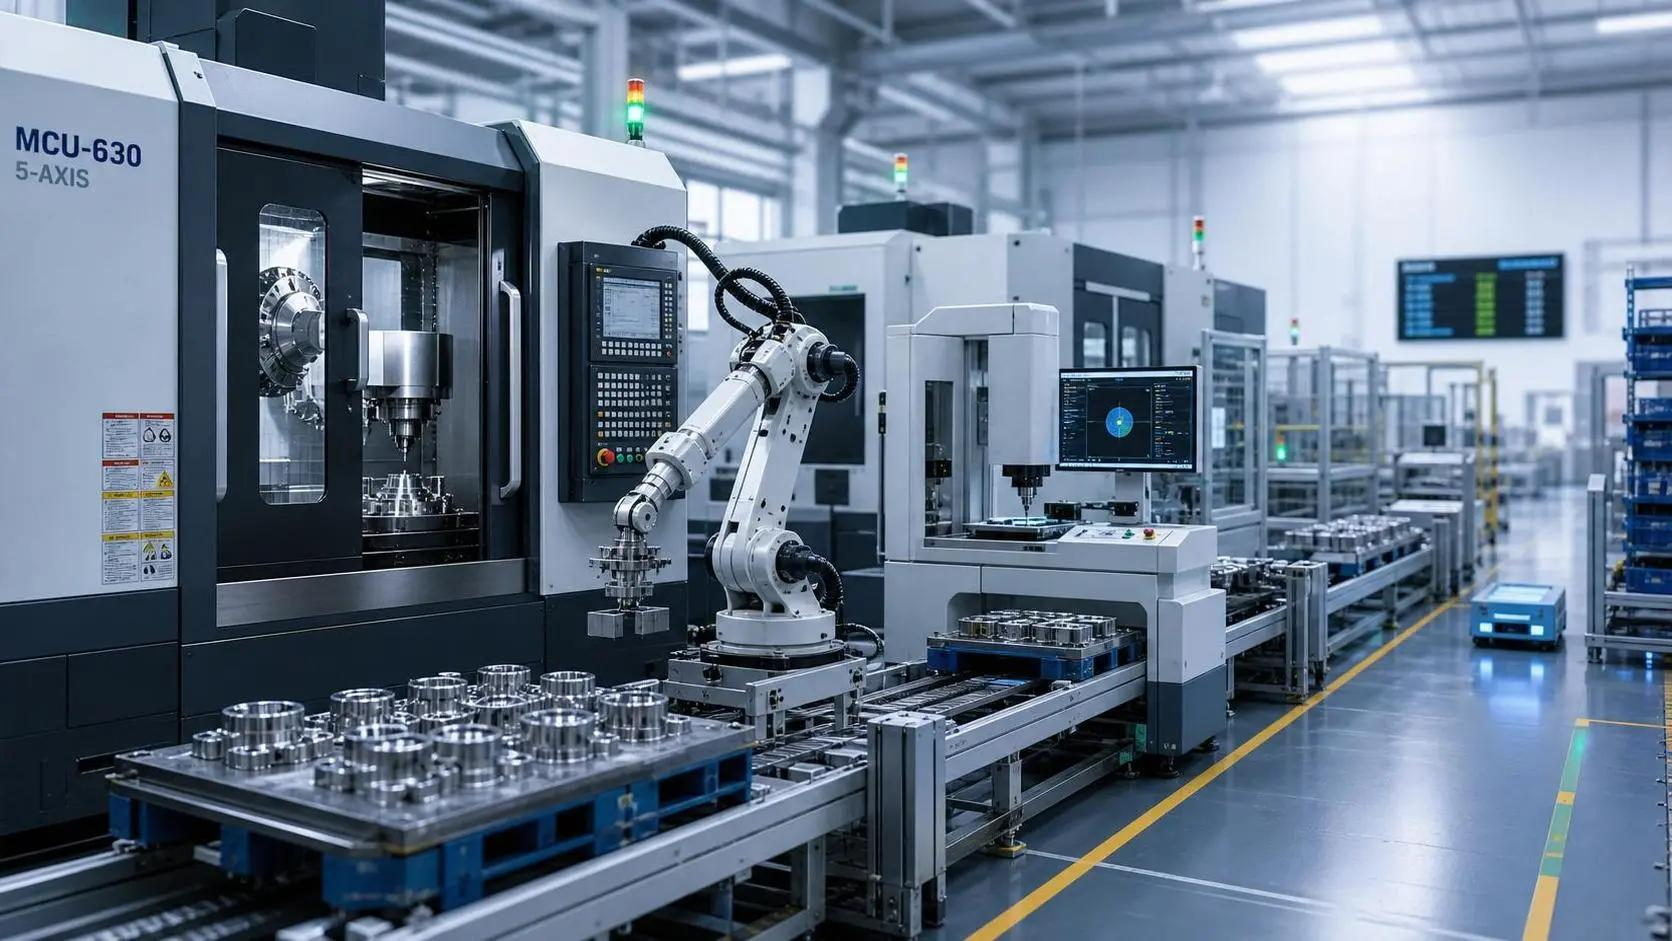


### Project Overview

This project explores the AI4I 2020 Predictive Maintenance dataset to identify patterns associated with machine failures and understand how operating conditions relate to maintenance risk.

### Business Objectives

- Assess data quality and understand the dataset.
- Identify the most frequent machine failure modes.
- Compare operating conditions between failed and non-failed machines.
- Analyze failure rates across tool wear and torque ranges.
- Translate analytical findings into potential maintenance insights.

### Tools & Technologies

Python | Pandas | NumPy | Matplotlib | Google Colab | GitHub

### Dataset

**Source:** AI4I 2020 Predictive Maintenance Dataset — UCI Machine Learning Repository.

The dataset contains 10,000 observations and is synthetic. It is used for educational and exploratory analytical purposes.

### Analytical Approach

1. Data loading and initial exploration
2. Data quality assessment
3. Exploratory data analysis (EDA)
4. Failure pattern analysis
5. Business insights and recommendations

### Scope & Limitations

This project is exploratory. Observed relationships do not establish causation, and the findings should not be interpreted as validated industrial operating thresholds.


In [119]:

# Manufacturing Performance Analytics
# Project 01 - Data Loading & Exploration

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!



## 1. Data Loading & Initial Exploration

The first step is to load the dataset and review its structure, dimensions, variables, and basic statistical properties.


In [120]:

url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

df = pd.read_csv(url, compression="zip")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [121]:

# Check dataset dimensions
print("Number of rows and columns:", df.shape)

# Display first 5 rows
display(df.head())


Number of rows and columns: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



## 2. Data Quality Assessment

This section evaluates the dataset's completeness, consistency, and reliability before performing further analysis.


In [122]:

# Dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [123]:

# Statistical summary
display(df.describe())


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [124]:

# Missing values
print("Missing values per column:")
display(df.isnull().sum())

# Duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Unique machine types
print("Machine types:")
print(df["Type"].value_counts())


Missing values per column:


,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Duplicate rows: 0
Machine types:
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64



## 3. Machine Failure Analysis

This section explores the distribution of machine failures and identifies the most frequently observed failure modes.


In [125]:

# Count machine failures
failure_counts = df["Machine failure"].value_counts()

# Calculate failure rate
failure_rate = df["Machine failure"].mean() * 100

print("Machine failure distribution:")
print(failure_counts)

print(f"\nMachine failure rate: {failure_rate:.2f}%")


Machine failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure rate: 3.39%



## 4. Tool Wear Analysis

This section investigates the relationship between tool wear and machine failure rates. The objective is to identify whether higher tool wear levels are associated with an increased frequency of machine failures.


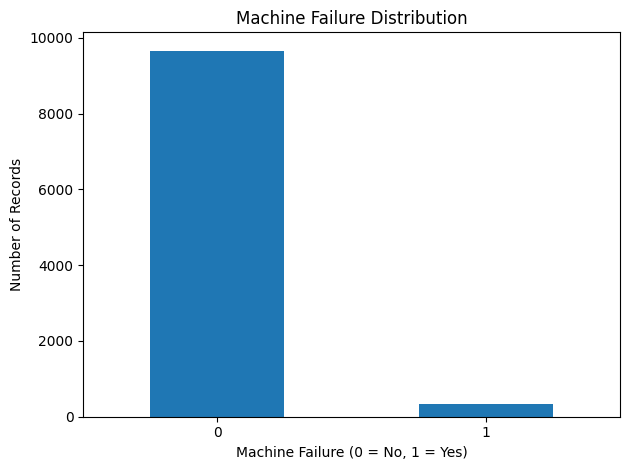

In [126]:

failure_counts.plot(
    kind="bar",
    title="Machine Failure Distribution",
    xlabel="Machine Failure (0 = No, 1 = Yes)",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [127]:

# 1. Dataset dimensions
print("1. DATASET DIMENSIONS")
print(df.shape)

# 2. Dataset information
print("\n2. DATASET INFORMATION")
df.info()

# 3. Missing values
print("\n3. MISSING VALUES")
print(df.isnull().sum())

# 4. Duplicate records
print("\n4. DUPLICATE RECORDS")
print(df.duplicated().sum())

# 5. Machine failure rate
print("\n5. MACHINE FAILURE RATE")
failure_rate = df["Machine failure"].mean() * 100
print(f"{failure_rate:.2f}%")


1. DATASET DIMENSIONS
(10000, 14)

2. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                

In [128]:

# 1. Failure rate by machine type

failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

failure_by_type.columns = [
    "Machine Type",
    "Total Records",
    "Total Failures",
    "Failure Rate"
]

failure_by_type["Failure Rate"] = (
    failure_by_type["Failure Rate"] * 100
).round(2)

display(failure_by_type)


,Machine Type,Total Records,Total Failures,Failure Rate
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


In [129]:

# 2. Failure modes analysis

failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_mode_counts = df[failure_modes].sum().sort_values(
    ascending=False
)

print("Failure modes frequency:")
display(failure_mode_counts)


Failure modes frequency:


,0
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19


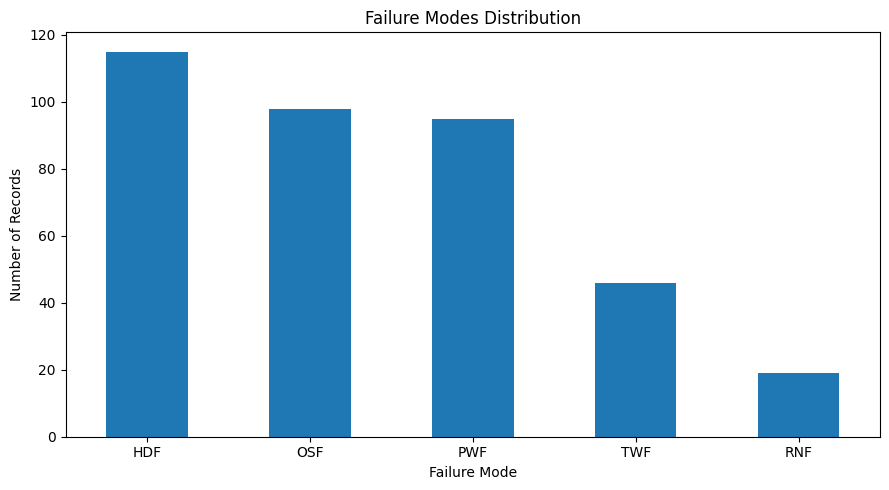

In [130]:

# 3. Visualize failure modes

failure_mode_counts.plot(
    kind="bar",
    title="Failure Modes Distribution",
    xlabel="Failure Mode",
    ylabel="Number of Records",
    figsize=(9, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Key Finding 03 — Tool Wear and Failure Rate

The analysis reveals a substantial increase in machine failure rates at higher tool wear levels.

The 201–250 minute wear group shows a failure rate of 15.26% (116 failures out of 760 observations), compared with approximately 2.17% in the 0–50 minute group. This represents approximately a sevenfold increase in the observed failure rate.

**Business implication:** Monitoring tool wear and scheduling preventive inspections before machines reach higher wear levels could be valuable maintenance strategies.

**Note:** The 251–300 minute group contains only two observations, so its 100% failure rate is not statistically representative.


In [131]:
# Calculate the percentage of each failure mode
failure_mode_summary = pd.DataFrame({
    "Failures": df[failure_modes].sum(),
    "Percentage of all records": (
        df[failure_modes].sum() / len(df) * 100
    ).round(2)
})

display(failure_mode_summary.sort_values(
    "Failures", ascending=False
))

,Failures,Percentage of all records
HDF,115,1.15
OSF,98,0.98
PWF,95,0.95
TWF,46,0.46
RNF,19,0.19


### Key Finding 01 – Failure Mode Distribution

Heat Dissipation Failure (HDF) is the most frequently observed failure mode in the AI4I 2020 dataset, with 115 records (1.15% of all observations). Overstrain Failure (OSF) and Power Failure (PWF) follow with 98 and 95 records, respectively.

Random Failures (RNF) are the least frequent, with only 19 records (0.19%).

**Business implication:** Heat dissipation, mechanical strain, and power-related conditions deserve further investigation when designing preventive maintenance strategies.

*Note: Failure-mode indicators may overlap; these counts should not be interpreted as mutually exclusive categories.*

In [132]:

# 4. Compare operating conditions by machine failure

variables = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

comparison = df.groupby("Machine failure")[variables].mean().round(2)

comparison.index = ["No Failure", "Failure"]

display(comparison)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
No Failure,299.97,310.00,1540.26,39.63,106.69
Failure,300.89,310.29,1496.49,50.17,143.78


### Key Finding 02 – Operating Conditions and Machine Failures

Records associated with machine failures show higher average tool wear (143.78 vs. 106.69 minutes) and torque (50.17 vs. 39.63 Nm) compared with records without failures.

Rotational speed is also lower in the failure group (1,496.49 vs. 1,540.26 rpm).

**Business implication:** Tool wear and torque should be prioritized for further investigation as potential indicators for maintenance planning.

*These are descriptive associations, not evidence of causation. Further analysis is required to validate the relationships.*

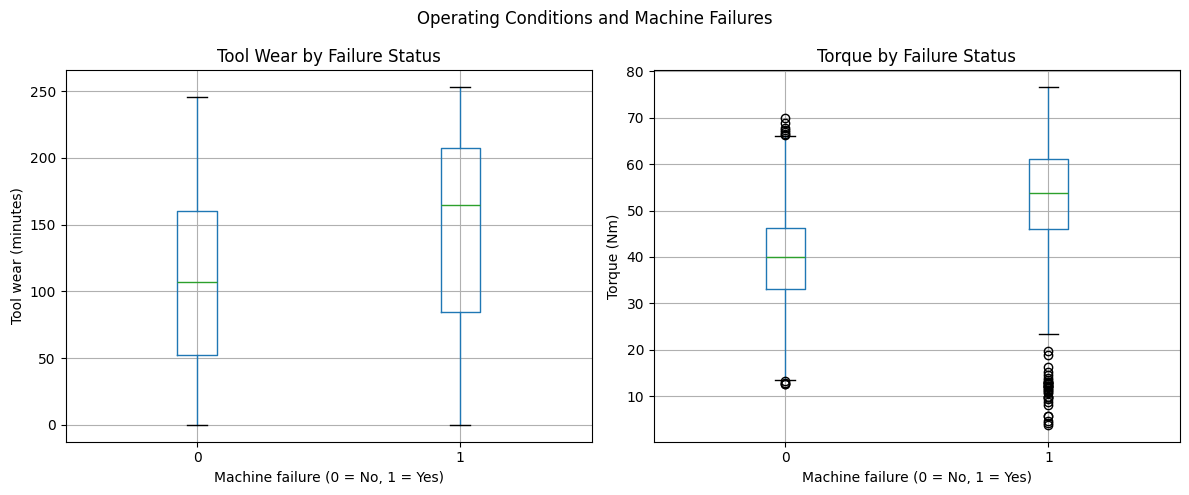

In [133]:

# 5. Compare tool wear and torque distributions

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.boxplot(
    column="Tool wear [min]",
    by="Machine failure",
    ax=axes[0]
)
axes[0].set_title("Tool Wear by Failure Status")
axes[0].set_xlabel("Machine failure (0 = No, 1 = Yes)")
axes[0].set_ylabel("Tool wear (minutes)")

df.boxplot(
    column="Torque [Nm]",
    by="Machine failure",
    ax=axes[1]
)
axes[1].set_title("Torque by Failure Status")
axes[1].set_xlabel("Machine failure (0 = No, 1 = Yes)")
axes[1].set_ylabel("Torque (Nm)")

plt.suptitle("Operating Conditions and Machine Failures")
plt.tight_layout()
plt.show()



### Key Finding 04 — Torque and Machine Failure Rate

The analysis reveals a non-linear relationship between torque levels and observed machine failure rates.

The 60–80 Nm group shows the highest failure rate (41.95%), followed by the 0–20 Nm group (14.59%). In contrast, the 20–40 Nm intervals show considerably lower failure rates (0.56–0.66%).

**Business implication:** Torque monitoring may help identify operating conditions associated with increased failure risk. Both unusually low and high torque ranges deserve further investigation.

**Note:** The extreme torque groups contain fewer observations (233 and 236 records, respectively). These findings are exploratory and should not be interpreted as universal operating thresholds or causal relationships.


In [134]:

# 6. Failure rate by tool wear level

df["Wear Group"] = pd.cut(
    df["Tool wear [min]"],
    bins=[-1, 50, 100, 150, 200, 250, 300],
    labels=[
        "0-50",
        "51-100",
        "101-150",
        "151-200",
        "201-250",
        "251-300"
    ]
)

wear_analysis = (
    df.groupby("Wear Group", observed=False)
    ["Machine failure"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

wear_analysis.columns = [
    "Wear Group (minutes)",
    "Records",
    "Failures",
    "Failure Rate"
]

wear_analysis["Failure Rate"] = (
    wear_analysis["Failure Rate"] * 100
).round(2)

display(wear_analysis)


,Wear Group (minutes),Records,Failures,Failure Rate
0,0-50,2396,52,2.17
1,51-100,2271,53,2.33
2,101-150,2295,50,2.18
3,151-200,2276,66,2.90
4,201-250,760,116,15.26
5,251-300,2,2,100.00


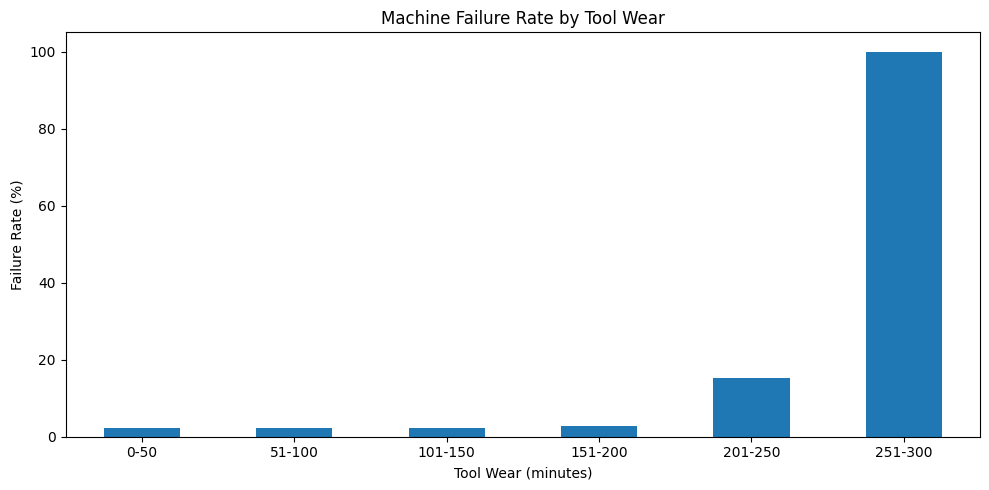

In [135]:

# 7. Visualize failure rate by tool wear

wear_analysis.plot(
    x="Wear Group (minutes)",
    y="Failure Rate",
    kind="bar",
    legend=False,
    title="Machine Failure Rate by Tool Wear",
    xlabel="Tool Wear (minutes)",
    ylabel="Failure Rate (%)",
    figsize=(10, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [136]:

# Compare failure rates across wear groups

display(
    wear_analysis[
        ["Wear Group (minutes)", "Records", "Failures", "Failure Rate"]
    ].sort_values("Failure Rate", ascending=False)
)


,Wear Group (minutes),Records,Failures,Failure Rate
5,251-300,2,2,100.00
4,201-250,760,116,15.26
3,151-200,2276,66,2.90
1,51-100,2271,53,2.33
2,101-150,2295,50,2.18
0,0-50,2396,52,2.17


### Key Finding 03 – Tool Wear and Failure Rate

The analysis reveals a substantial increase in machine failure rates at higher tool wear levels.

The 201–250 minute wear group shows a failure rate of 15.26% (116 failures out of 760 observations), compared with approximately 2.17% in the 0–50 minute group.

This represents approximately a sevenfold increase in the observed failure rate.

**Business implication:** Monitoring tool wear and scheduling preventive inspections before machines reach higher wear levels could be valuable maintenance strategies.

*Note: The 251–300 minute group contains only two observations, so its 100% failure rate is not statistically representative.*

In [137]:

# 8. Failure rate by torque level

df["Torque Group"] = pd.cut(
    df["Torque [Nm]"],
    bins=[0, 20, 30, 40, 50, 60, 80],
    labels=[
        "0-20",
        "20-30",
        "30-40",
        "40-50",
        "50-60",
        "60-80"
    ]
)

torque_analysis = (
    df.groupby("Torque Group", observed=False)["Machine failure"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

torque_analysis.columns = [
    "Torque Group (Nm)",
    "Records",
    "Failures",
    "Failure Rate"
]

torque_analysis["Failure Rate"] = (
    torque_analysis["Failure Rate"] * 100
).round(2)

display(torque_analysis)


,Torque Group (Nm),Records,Failures,Failure Rate
0,0-20,233,34,14.59
1,20-30,1369,9,0.66
2,30-40,3385,19,0.56
3,40-50,3472,66,1.90
4,50-60,1305,112,8.58
5,60-80,236,99,41.95


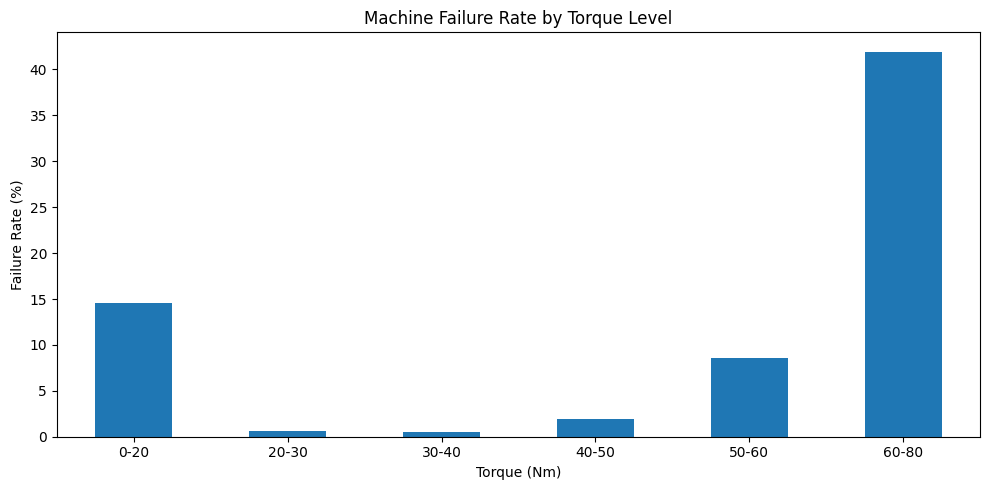

In [138]:

# 9. Visualize failure rate by torque

torque_analysis.plot(
    x="Torque Group (Nm)",
    y="Failure Rate",
    kind="bar",
    legend=False,
    title="Machine Failure Rate by Torque Level",
    xlabel="Torque (Nm)",
    ylabel="Failure Rate (%)",
    figsize=(10, 5)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Key Finding 04 – Torque and Machine Failure Rate

The analysis reveals a non-linear relationship between torque levels and observed machine failure rates.

The 60–80 Nm group shows the highest failure rate (41.95%), followed by the 0–20 Nm group (14.59%). In contrast, the 20–40 Nm intervals show considerably lower failure rates (0.56–0.66%).

**Business implication:** Torque monitoring may help identify operating conditions associated with increased failure risk. Both unusually low and high torque ranges deserve further investigation.

*Note: The extreme torque groups contain fewer observations (233 and 236 records, respectively). These findings are exploratory and should not be interpreted as universal operating thresholds or causal relationships.*


## 6. Final Conclusions & Business Recommendations

### Key Conclusions

The exploratory analysis of the AI4I 2020 dataset highlights several patterns associated with machine failure:

1. **Failure modes:** Heat Dissipation Failure (HDF) is the most frequently observed failure mode in the dataset.
2. **Tool wear:** Failure rates increase considerably in the 201–250 minute wear group compared with the 0–50 minute group.
3. **Torque:** Both low and high torque ranges show elevated failure rates, suggesting a non-linear relationship that deserves further investigation.
4. **Operating conditions:** Failed-machine records show higher average torque and tool wear, alongside lower rotational speed.

### Business Recommendations

Based on these exploratory findings, manufacturing teams could consider:

- Monitoring tool wear levels as part of preventive maintenance planning.
- Investigating unusual torque readings and their relationship with machine performance.
- Reviewing heat dissipation and operating conditions associated with failure events.
- Combining multiple machine parameters to support maintenance decisions.

### Analytical Limitations

- The dataset is synthetic and does not represent actual production operations.
- The analysis identifies associations, not causal relationships.
- Some extreme operating ranges contain relatively few observations.
- Further statistical validation and testing on real industrial data would be required before implementing maintenance thresholds.

### Final Takeaway

This project demonstrates how exploratory data analysis can transform raw manufacturing data into actionable insights that may support preventive maintenance planning and operational performance monitoring.


In [139]:
!pip install duckdb

In [140]:
import duckdb

# Create an in-memory SQL database
conn = duckdb.connect(database=":memory:")

# Register the existing Pandas DataFrame as a SQL table
conn.register("ai4i2020", df)

print("SQL database ready!")

SQL database ready!


In [141]:
conn.execute("""
SELECT *
FROM ai4i2020
LIMIT 10;
""").df()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Wear Group,Torque Group
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,0-50,40-50
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0-50,40-50
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0-50,40-50
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0-50,30-40
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0-50,30-40
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0,0-50,40-50
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0,0-50,40-50
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0,0-50,40-50
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0,0-50,20-30
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0,0-50,20-30


In [142]:
conn.execute("""
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT UDI) AS unique_records,
    COUNT(*) - COUNT(DISTINCT UDI) AS duplicate_udi
FROM ai4i2020;
""").df()

,total_records,unique_records,duplicate_udi
0,10000,10000,0


In [143]:
df_sql = df.rename(columns={
    "Product ID": "Product_ID",
    "Air temperature [K]": "Air_temperature_K",
    "Process temperature [K]": "Process_temperature_K",
    "Rotational speed [rpm]": "Rotational_speed_rpm",
    "Torque [Nm]": "Torque_Nm",
    "Tool wear [min]": "Tool_wear_min",
    "Machine failure": "Machine_failure"
})

conn.unregister("ai4i2020")
conn.register("ai4i2020", df_sql)

print("Dataset ready for SQL analysis!")

Dataset ready for SQL analysis!


In [144]:
query = """
SELECT COUNT(*) AS total_records
FROM ai4i2020;
"""

conn.execute(query).df()

,total_records
0,10000


In [145]:
query = """
SELECT
    COUNT(*) AS total_records,
    SUM(Machine_failure) AS total_failures,
    ROUND(100.0 * SUM(Machine_failure) / COUNT(*), 2)
        AS failure_rate_percentage
FROM ai4i2020;
"""

conn.execute(query).df()

,total_records,total_failures,failure_rate_percentage
0,10000,339.0,3.39


In [146]:
queries = {
    "Operating Conditions": """
        SELECT
            Machine_failure,
            COUNT(*) AS total_records,
            ROUND(AVG(Torque_Nm), 2) AS avg_torque,
            ROUND(AVG(Tool_wear_min), 2) AS avg_tool_wear,
            ROUND(AVG(Rotational_speed_rpm), 2) AS avg_speed
        FROM ai4i2020
        GROUP BY Machine_failure
        ORDER BY Machine_failure
    """,

    "Failure by Torque": """
        SELECT
            CASE
                WHEN Torque_Nm < 20 THEN '0-20'
                WHEN Torque_Nm < 30 THEN '20-30'
                WHEN Torque_Nm < 40 THEN '30-40'
                WHEN Torque_Nm < 50 THEN '40-50'
                WHEN Torque_Nm < 60 THEN '50-60'
                ELSE '60-80'
            END AS torque_group,
            COUNT(*) AS total_records,
            SUM(Machine_failure) AS failures,
            ROUND(100.0 * SUM(Machine_failure) / COUNT(*), 2)
                AS failure_rate
        FROM ai4i2020
        GROUP BY torque_group
        ORDER BY MIN(Torque_Nm)
    """,

    "Failure by Tool Wear": """
        SELECT
            CASE
                WHEN Tool_wear_min <= 50 THEN '0-50'
                WHEN Tool_wear_min <= 100 THEN '51-100'
                WHEN Tool_wear_min <= 150 THEN '101-150'
                WHEN Tool_wear_min <= 200 THEN '151-200'
                WHEN Tool_wear_min <= 250 THEN '201-250'
                ELSE '251-300'
            END AS wear_group,
            COUNT(*) AS total_records,
            SUM(Machine_failure) AS failures,
            ROUND(100.0 * SUM(Machine_failure) / COUNT(*), 2)
                AS failure_rate
        FROM ai4i2020
        GROUP BY wear_group
        ORDER BY MIN(Tool_wear_min)
    """
}

for name, query in queries.items():
    print(f"\n--- {name} ---")
    display(conn.execute(query).df())


--- Operating Conditions ---


,Machine_failure,total_records,avg_torque,avg_tool_wear,avg_speed
0,0,9661,39.63,106.69,1540.26
1,1,339,50.17,143.78,1496.49



--- Failure by Torque ---


,torque_group,total_records,failures,failure_rate
0,0-20,228,34.0,14.91
1,20-30,1348,9.0,0.67
2,30-40,3364,19.0,0.56
3,40-50,3487,66.0,1.89
4,50-60,1334,111.0,8.32
5,60-80,239,100.0,41.84



--- Failure by Tool Wear ---


,wear_group,total_records,failures,failure_rate
0,0-50,2396,52.0,2.17
1,51-100,2271,53.0,2.33
2,101-150,2295,50.0,2.18
3,151-200,2276,66.0,2.90
4,201-250,760,116.0,15.26
5,251-300,2,2.0,100.00


In [148]:

query = """
SELECT
    CASE
        WHEN Torque_Nm <= 20 THEN '0-20'
        WHEN Torque_Nm <= 30 THEN '20-30'
        WHEN Torque_Nm <= 40 THEN '30-40'
        WHEN Torque_Nm <= 50 THEN '40-50'
        WHEN Torque_Nm <= 60 THEN '50-60'
        ELSE '60-80'
    END AS torque_group,
    COUNT(*) AS total_records,
    SUM(Machine_failure) AS failures,
    ROUND(
        100.0 * SUM(Machine_failure) / COUNT(*), 2
    ) AS failure_rate
FROM ai4i2020
GROUP BY torque_group
ORDER BY MIN(Torque_Nm);
"""

conn.execute(query).df()


,torque_group,total_records,failures,failure_rate
0,0-20,233,34.0,14.59
1,20-30,1369,9.0,0.66
2,30-40,3385,19.0,0.56
3,40-50,3472,66.0,1.90
4,50-60,1305,112.0,8.58
5,60-80,236,99.0,41.95
